# Warnings about normalizing data

## Introduction

For many machine learning algorithms, normalizing the data of analysis is a must. A supervised example would be neural networks. It is known that normalizing the input data to the networks improve the results. If you don't believe me it's ok (no offense taken), but you may prefer to believe Yann Le Cunn (Director of AI Research in Facebook and founding father of convolutional networks) by checking section 4.3 of [this paper](http://yann.lecun.com/exdb/publis/pdf/lecun-98b.pdf). You can catch up the idea with the first sentence of the section: *Convergence [of backprop] is usually faster if the average of each input variable over the training set is close to zero*. Among other things, one reason is that when the neural network tries to correct the error performed in a prediction, it updates the weights in the network by an amount proportional to the input vector, which is bad if input is large.

Another example, in this case of an unsupervised algorithm, is K-means. This algorithms tries to group data in clusters so that the data in each cluster shares some common characteristics. This algorithm performs two steps:

1. Assign centers of clusters in some point in space (random at first time, calculating the centroid of each cluster the rest of times)
2. Associate each point to the closest center.

In this second step, the distances between each point and the centers are calculated usually as a [Minkowski distance](https://en.wikipedia.org/wiki/Minkowski_distance) (commonly the famous Euclidean distance). Each feature weights the same in the calculation, so features measured in high ranges will influence more than those measured in low ranges e.g. the same feature would influence more in the calculation if measured in millimeters than in kilometers (because the numbers would be bigger). So the scale of the features must be in a comparable range.


Now you now that normalization is important, let us see what options we have to normalize our data.

## A couple of ways to normalize data

### Feature scaling

Each feature is normalized within the limits of the feature.

\begin{equation}
X_{normalized} = \frac{X - X_{min}}{X_{max} - X_{min}}
\end{equation}

This is a common technique used to scale data into a range. But the problem when normalizing each feature within its **empirical** limits (so that, the maximum and the minimum found in this column) is that noise may be amplified. 

One example: imagine we have internet data from a particular house and we want to make a model to predict something (maybe the price to charge). One of our hypothetical features could be the [bandwidth](https://en.wikipedia.org/wiki/Bandwidth_(computing) of the fiber optic connection. Suppose the house purchased a 30Mbit internet connection, so the bit rate is approximatelly the same every time we measure it (lucky guy).

(0.0, 50.0)

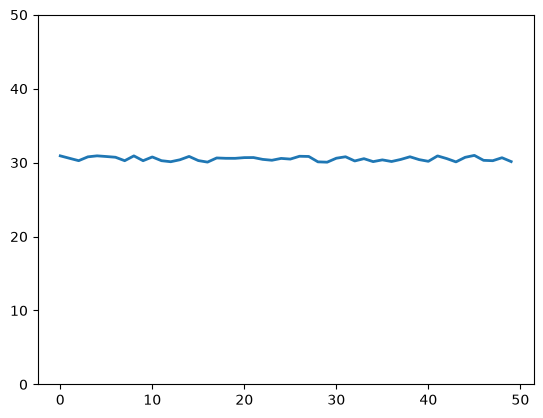

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

#initialize the seed
np.random.seed(314)

# generate 50 numbers between 30 and 31
datasetFlat = np.random.rand(50) + 30

#plot them
x = np.arange(len(datasetFlat))
plt.plot(x, datasetFlat, '-', linewidth=2)

#force limits on the figure
axes = plt.gca()
axes.set_ylim([0,50])

It looks like a pretty stable connection right?. As the bandwidth is measured in a scale far from 1, let us scale it between 0 and 1 using our feature scaling method (sklearn.preprocessing.MinMaxScaler).

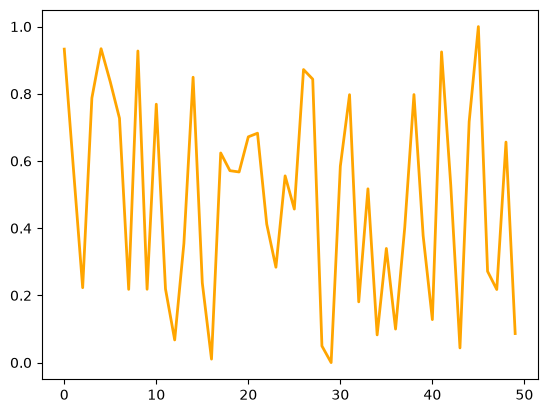

In [2]:
from sklearn.preprocessing import MinMaxScaler
#create scaler
scaler = MinMaxScaler()

#apply scaler
datasetFlatScaled = scaler.fit_transform(datasetFlat.reshape(-1,1))

#plot scaled data
plt.plot(x, datasetFlatScaled, '-', linewidth=2, color="orange")

After the scaling, our data is distorted. What it was an almost flat signal, now looks like a connection with a lot of variation. This fact tells us that feature scaling is not adequate to nearly constant signals.

### Standard scaler

Next try. Ok, scaling in a range didn't work for a noisy flat signal, but what about standardizing the signal?.
Each feature woulde be normalize by:

\begin{equation}
X_{normalized} =  \frac{X - X_{mean}}{X_{std dev}}
\end{equation}

 This could work on the previous case, but don't open the bottle yet. Mean and standard deviation are very sensitive to outliers ([small demonstration](http://www.statisticslectures.com/topics/outliereffects/)). This means that outliers may attenuate the non-outlier part of the data.  

Now imagine we have data about how often the word "hangover" is posted on Facebook ([for real](http://www.gelfmagazine.com/gelflog/archives/understanding_facebooks_lexicon.php#stq=&stp=0)). The frequency is like a sine wave, with lows during the weekdays and highs on weekends. It also has big outliers after "Halloween" and similar dates. We have idealized this siutation with the next dataset (3 parties in 50 days. Not bad).


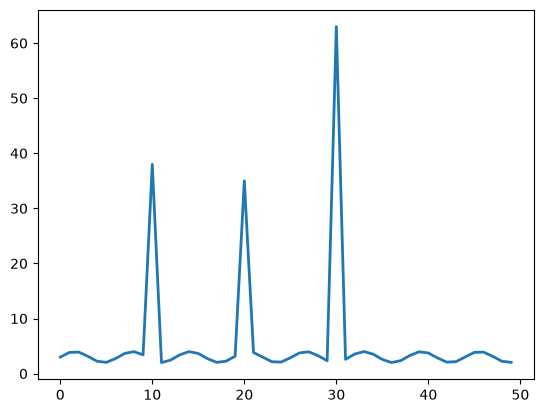

In [3]:
#generate sine wave with outliers
datasetSinOutlier = np.sin(range(0,10)).tolist() + \
                    [35] +  \
                    np.sin(range(11,20)).tolist() + \
                    [32]  +  \
                    np.sin(range(21,30)).tolist() + \
                    [60]  +  \
                    np.sin(range(31,50)).tolist() 

                
datasetSinOutlier = [i+3 for i in datasetSinOutlier]
                    
#this is used only to plot
x = np.arange(len(datasetSinOutlier))

#plot
plt.plot(x, datasetSinOutlier, '-', linewidth=2)

Despite having outliers, we would like to be able to distinguish clearly that there exist a measurable difference between weekdays and weekends. Now we want to predict something (that's our business) and we would like to preserve the fact that during the weekends the values are higer, so we think of standardizing the data (sklearn.preprocessing.StandardScaler). We check the basic parameters of standardization.

In [4]:
#printing basic parameters involved in Standard Scaler
print ("Mean", np.mean(datasetSinOutlier))
print ("Std", np.std(datasetSinOutlier))

Mean 5.555647190769012
Std 10.531262602796922


So, our mean is 5 when our data (without outliers) does not go over 4 (not even in weekends). Bad feeling.


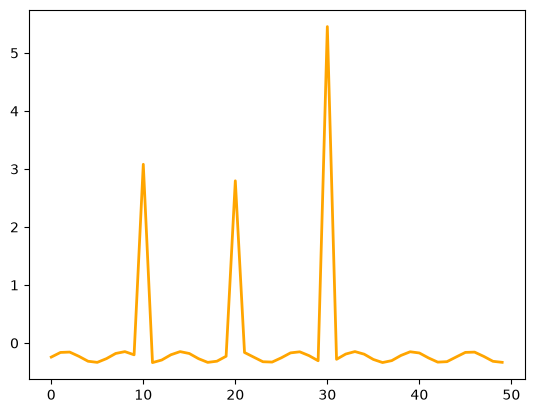

In [5]:
from sklearn.preprocessing import StandardScaler
#create scaler
scaler = StandardScaler()

#apply scaler
datasetSinOutlierScaled = scaler.fit_transform(np.array(datasetSinOutlier).reshape(-1,1))

#plot scaled data
plt.plot(x, datasetSinOutlierScaled, '-', linewidth=2, color="orange")

What happened? First, we were not able to scale the data between 0 and 1. Second, we now have negative numbers, which is not a dead end, but complicates the analysis. And third, now we  are not able to clearly distinguish the differences between weekdays and weekend (all close to 0), because outliers have interfered with the data. 

From a very promising data, now we have an almost irrelevant one. One solution to his situation could be to preprocess the data and eliminate the outliers ([things change with outliers](http://www.r-bloggers.com/identify-describe-plot-and-remove-the-outliers-from-the-dataset/)).

### Scaling over the maximum value

The next idea that comes to mind is to scale the data by dividing it by its maximum value. Let see how it behaves with our datasets (sklearn.preprocessing.MaxAbsScaler).

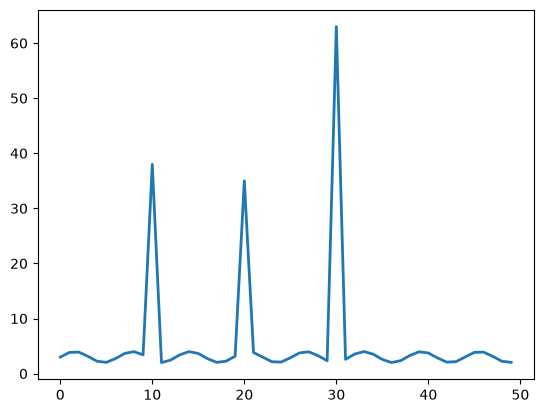

In [6]:
#generate sine wave with outliers
datasetSinOutlier = np.sin(range(0,10)).tolist() + \
                    [35] +  \
                    np.sin(range(11,20)).tolist() + \
                    [32]  +  \
                    np.sin(range(21,30)).tolist() + \
                    [60]  +  \
                    np.sin(range(31,50)).tolist() 

datasetSinOutlier = [i+3 for i in datasetSinOutlier]

#this is used only to plot
x = np.arange(len(datasetSinOutlier))

#plot
plt.plot(x, datasetSinOutlier, '-', linewidth=2)

Same data as before.

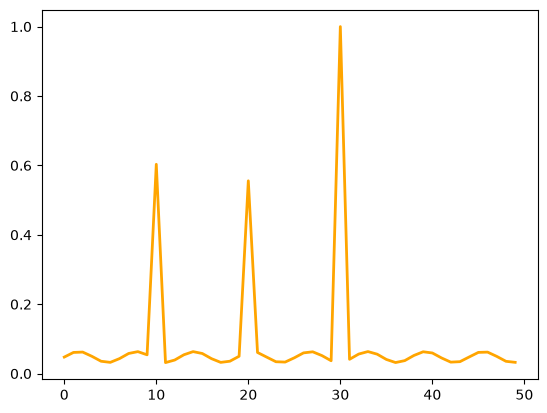

In [7]:
#scale data
datasetSinOutlierScaledMax=[i / max(datasetSinOutlier) for i in datasetSinOutlier]

#plot
plt.plot(x, datasetSinOutlierScaledMax, '-', linewidth=2, color="orange")

Good!, our data is in range 0,1... But, wait! what happended with the differences between weekdays and weekends?, they are all close to zero!. As in the case of standardization, outliers flatten the differences among the data when scaling over the maximum.

### Normalizer

The next tool in the box of the data scientist is to normalize samples individually to unit norm ([check this if you don't remember what a norm is](https://en.wikipedia.org/wiki/Norm_(mathematics)).


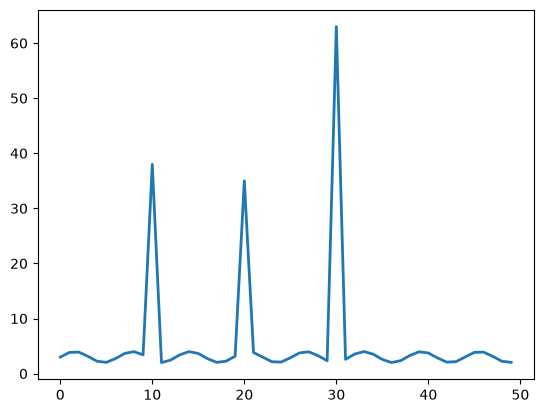

In [8]:
#generate sine wave with outliers
datasetSinOutlier = np.sin(range(0,10)).tolist() + \
                    [35] +  \
                    np.sin(range(11,20)).tolist() + \
                    [32]  +  \
                    np.sin(range(21,30)).tolist() + \
                    [60]  +  \
                    np.sin(range(31,50)).tolist() 

datasetSinOutlier = [i+3 for i in datasetSinOutlier]

#this is used only to plot
x = np.arange(len(datasetSinOutlier))

#plot
plt.plot(x, datasetSinOutlier, '-', linewidth=2)

This data rings a bell in your head right? let's normalize it (here by hand, but also available as sklearn.preprocessing.Normalizer).

highest point:  0.7482715448739478


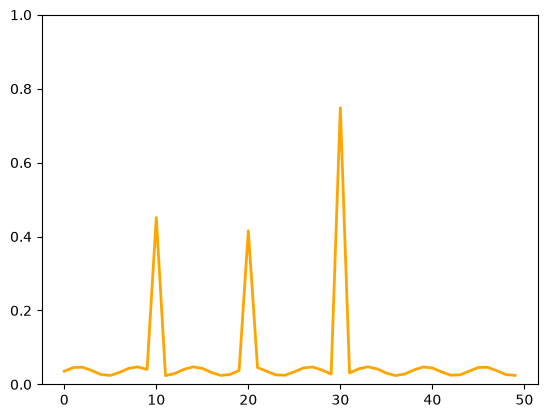

In [9]:
#scale data
datasetSinOutlierNorm = datasetSinOutlier / np.linalg.norm(datasetSinOutlier)

#plot
plt.plot(x, datasetSinOutlierNorm, '-', linewidth=2, color="orange")

#force limits on the figure
axes = plt.gca()
axes.set_ylim([0,1])

#print highest peak
print("highest point: ", np.max(datasetSinOutlierNorm))

At this point of the post, you know the story, but this case is worse than the previous ones. In this case we don't even get the highest outlier as 1, it is scaled to 0.74, which flattens the rest of the data even more.

### Robust scaler

The last option we are going to evaluate is Robust scaler. This method removes the median and scales the data according to the Interquartile Range (IQR). It is supposed to be robust to outliers.

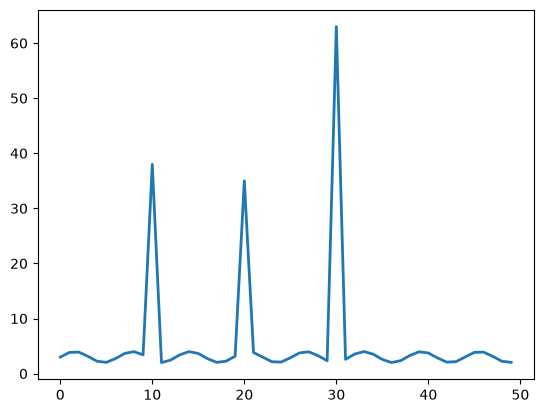

In [10]:
#generate sine wave with outliers
datasetSinOutlier = np.sin(range(0,10)).tolist() + \
                    [35] +  \
                    np.sin(range(11,20)).tolist() + \
                    [32]  +  \
                    np.sin(range(21,30)).tolist() + \
                    [60]  +  \
                    np.sin(range(31,50)).tolist() 

datasetSinOutlier = [i+3 for i in datasetSinOutlier]

#this is used only to plot
x = np.arange(len(datasetSinOutlier))

#plot
plt.plot(x, datasetSinOutlier, '-', linewidth=2)

Now we apply the scaler (sklearn.preprocessing.RobustScaler) to our data.

[-8.96206847e-02  4.80195431e-01  5.26125238e-01  5.94108306e-03
 -6.02102120e-01 -7.38972255e-01 -2.78831551e-01  3.55268751e-01
  5.80339758e-01  1.89452223e-01  2.36112132e+01 -7.66780736e-01
 -4.52969988e-01  1.94902434e-01  5.81185613e-01  3.50732575e-01
 -2.84579219e-01 -7.40647036e-01 -5.98164228e-01  1.18711682e-02
  2.15797132e+01  4.76934639e-01 -9.56144965e-02 -6.62652949e-01
 -7.02848181e-01 -1.79244880e-01  4.26758492e-01  5.58005231e-01
  9.38276894e-02 -5.39011441e-01  4.05403803e+01 -3.63221517e-01
  2.83787092e-01  5.87486313e-01  2.68656483e-01 -3.79571723e-01
 -7.61220281e-01 -5.25403268e-01  1.11070243e-01  5.63029440e-01
  4.14945123e-01 -1.97034671e-01 -7.10258541e-01 -6.52870828e-01
 -7.76335308e-02  4.86582833e-01  5.21040340e-01 -5.94108306e-03
 -6.09857146e-01 -7.35470205e-01]


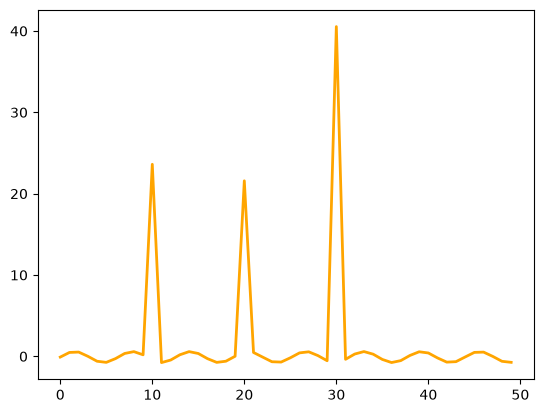

In [11]:
from sklearn.preprocessing import RobustScaler
#create scaler
scaler = RobustScaler()

#apply scaler
datasetSinOutlierRobust = scaler.fit_transform(np.array(datasetSinOutlier).reshape(-1,1))

#print data
print (datasetSinOutlierRobust.ravel())

#plot
plt.plot(x, datasetSinOutlierRobust, '-', linewidth=2, color="orange")

You may not see it in the plot (but you can see it in the output), but this scaler introduced negative numbers and did not limit the data to the range [0, 1]. (ok, I quit).

There are others methods to normalize your data (based on PCA, taking into accounts possible physical bounds, etc), but now you know how to evaluate wheter your algorithm is going to influence negatively in your data.



## Things to remember (basically: know your data)

**Normalization may (possibly [dangerously]) distort your data**.

There is no ideal method to normalize or scale all the dataset. So it is the job of the data scientist to know how the data is distributed, know the existence of outliers, check ranges, know the physical limits (if any) and so on. With this knowledge, one can select the best technique to normalize the feature, probably using a different method for each feature. 

If you know nothing about your data, I would recommend you to first check the existence of outliers (remove them if neccesary) and then scale over the maximum of each feature (while crossing your fingers). 



Santiago Morante, PhD <br>
Data Scientist